# Booked or Cancelled?
## Predicting hotel booking cancellations and discovering booking patterns

VSEC Data Science Laboratory. Use the project Python environment. This notebook reads the full real dataset and executes analysis code. All results refer to historical data.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Start Jupyter in the project directory.'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from src.data import load_data, chronological_split
from src.features import make_features
from src.config import MODEL_PATH, METADATA_PATH, REPORTS, SEED
from src.model import make_pipeline
from src.evaluation import evaluate
from sklearn.linear_model import LogisticRegression
data = load_data()
metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
print(data.shape)
data.head()

(119390, 36)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date,booking_date_proxy,total_nights,total_guests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01,2014-07-24,0,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01,2013-06-24,0,2.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01,2015-06-24,1,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01,2015-06-18,1,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,2015-07-01,2015-06-17,2,2.0


## 1. Target and data quality
One row describes a reservation. is_canceled=1 indicates cancellation. is_canceled=0 is not a guaranteed check-in. Identical-looking rows remain because a booking identifier is unavailable.

In [2]:
pd.DataFrame({'dtype': data.dtypes.astype(str), 'missing': data.isna().sum()})

,dtype,missing
hotel,str,0
is_canceled,int64,0
lead_time,int64,0
arrival_date_year,int64,0
arrival_date_month,str,0
arrival_date_week_number,int64,0
arrival_date_day_of_month,int64,0
stays_in_weekend_nights,int64,0
stays_in_week_nights,int64,0
adults,int64,0


In [3]:
print('Raw cancellation rate:', round(data.is_canceled.mean(),4))
print('Exact duplicate-looking source rows:', metadata['exact_duplicate_rows'])
print('Model exclusions:', metadata['excluded_rows'])
data.groupby('hotel').is_canceled.agg(['size','mean'])

Raw cancellation rate: 0.3704
Exact duplicate-looking source rows: 31994
Model exclusions: 826


,size,mean
hotel,,
City Hotel,79330,0.417270
Resort Hotel,40060,0.277634


## 2. Observed booking patterns
Calendar coverage is incomplete in 2015 and 2017. Group associations are descriptive rather than causal.

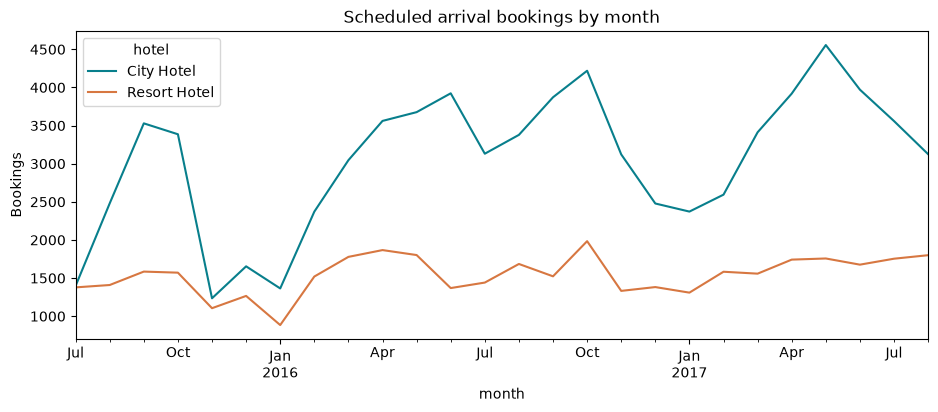

In [4]:
monthly = data.assign(month=data.arrival_date.dt.to_period('M').dt.to_timestamp()).groupby(['month','hotel']).size().unstack(fill_value=0)
monthly.plot(figsize=(11,4), color=['#087f8c','#d77741'], title='Scheduled arrival bookings by month')
plt.ylabel('Bookings')
plt.show()

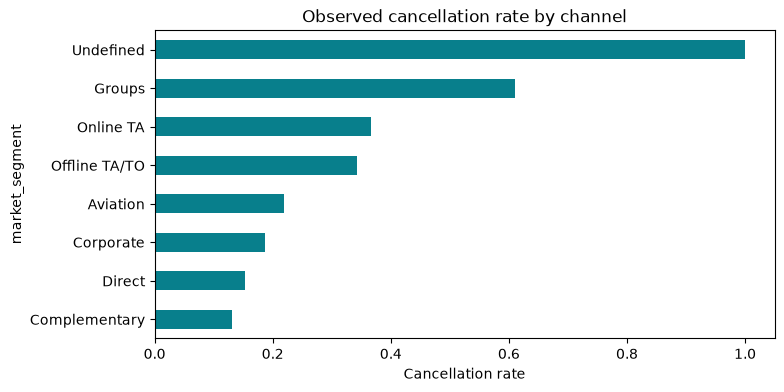

,bookings,cancellations,rate
market_segment,,,
Complementary,743,97,0.130552
Direct,12606,1934,0.153419
Corporate,5295,992,0.187347
Aviation,237,52,0.219409
Offline TA/TO,24219,8311,0.343160
Online TA,56477,20739,0.367211
Groups,19811,12097,0.610620
Undefined,2,2,1.000000


In [5]:
channels = data.groupby('market_segment').is_canceled.agg(bookings='size', cancellations='sum', rate='mean').sort_values('rate')
channels['rate'].plot.barh(figsize=(8,4),color='#087f8c',title='Observed cancellation rate by channel')
plt.xlabel('Cancellation rate')
plt.show()
channels

## 3. Chronological partitions and label availability
Booking date proxy = arrival minus lead time. Earlier cohorts require completed planned stays and recorded outcomes before the next period. This removes unresolved earlier records and limits cohort coverage. Final status dates serve this evaluation guard only.

In [6]:
invalid = (data.total_guests < 1) | (data.total_nights < 1) | (data.adr < 0) | data.arrival_date.isna()
parts = chronological_split(data.loc[~invalid].copy())
pd.DataFrame([{'partition':k,'rows':len(v),'start':v.booking_date_proxy.min(),'end':v.booking_date_proxy.max(),'cancelled':v.is_canceled.mean()} for k,v in parts.items()])

,partition,rows,start,end,cancelled
0,train,57745,2014-03-18,2016-08-30,0.358282
1,validation,8321,2016-09-01,2016-12-30,0.235068
2,test,26409,2017-01-01,2017-08-31,0.317657


In [7]:
X_train = make_features(parts['train'])
y_train = parts['train'].is_canceled.astype(int)
X_validation = make_features(parts['validation'])
y_validation = parts['validation'].is_canceled.astype(int)
assert 'reservation_status' not in X_train
assert 'reservation_status_date' not in X_train
assert parts['train'].booking_date_proxy.max() < parts['validation'].booking_date_proxy.min()
assert parts['validation'].booking_date_proxy.max() < parts['test'].booking_date_proxy.min()
X_train.head()

,lead_time,arrival_month,arrival_day,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,adr,hotel,meal,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type
4182,709.0,2.0,25.0,8.0,20.0,2.0,0.0,0.0,0.0,0.0,0.0,68.00,Resort Hotel,HB,Direct,Direct,E,No Deposit,Transient
17427,532.0,10.0,2.0,2.0,7.0,2.0,0.0,0.0,0.0,0.0,0.0,47.46,Resort Hotel,BB,Offline TA/TO,TA/TO,D,No Deposit,Contract
890,460.0,8.0,3.0,2.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,77.54,Resort Hotel,HB,Offline TA/TO,TA/TO,E,No Deposit,Contract
15974,460.0,8.0,3.0,2.0,5.0,2.0,0.0,0.0,0.0,0.0,0.0,134.73,Resort Hotel,HB,Offline TA/TO,TA/TO,E,No Deposit,Contract
15976,460.0,8.0,3.0,2.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,77.54,Resort Hotel,HB,Offline TA/TO,TA/TO,E,No Deposit,Contract


## 4. Train an interpretable baseline
The pipeline fits imputers, numeric scaling and one-hot encoding on training data only. The complete three-algorithm experiment lives in train.py. This cell really fits logistic regression rather than displaying saved results.

In [8]:
logistic = make_pipeline(LogisticRegression(max_iter=1500,C=1.0,random_state=SEED))
logistic.fit(X_train,y_train)
validation_probability = logistic.predict_proba(X_validation)[:,1]
evaluate(y_validation,validation_probability)

{'accuracy': 0.7686576132676362,
 'balanced_accuracy': 0.5102262340220113,
 'precision': 0.7719298245614035,
 'recall': 0.022494887525562373,
 'f1': 0.04371584699453552,
 'roc_auc': 0.6624768071171427,
 'average_precision': 0.37862356607338726,
 'brier_score': 0.17060105602136388,
 'threshold': 0.5,
 'confusion_matrix': [[6352, 13], [1912, 44]]}

## 5. Compare algorithms
Saved comparison rows all use threshold 0.50. Model choice uses validation ROC AUC. Test scores are reported after selection.

In [9]:
comparison = pd.read_csv(REPORTS/'model_comparison.csv')
comparison[['model','selected','validation_roc_auc','test_roc_auc','test_f1','test_brier_score']]

,model,selected,validation_roc_auc,test_roc_auc,test_f1,test_brier_score
0,Majority baseline,False,0.500000,0.500000,0.000000,0.317657
1,Logistic regression,False,0.662477,0.746562,0.300896,0.175429
2,Random forest,True,0.695105,0.776241,0.287307,0.167770
3,Gradient boosting,False,0.669107,0.778474,0.387045,0.166064


## 6. Re-evaluate the distributed model
This recomputes held-out metrics from the saved fitted pipeline. The threshold comes from validation, not from the test period.

In [10]:
bundle = joblib.load(MODEL_PATH)
X_test = make_features(parts['test'])
y_test = parts['test'].is_canceled.astype(int)
probability = bundle['pipeline'].predict_proba(X_test)[:,1]
scores = evaluate(y_test,probability,bundle['threshold'])
print(bundle['model_name'], 'threshold', bundle['threshold'])
scores

Random forest threshold 0.16


{'accuracy': 0.5593926312999357,
 'balanced_accuracy': 0.6533408959118681,
 'precision': 0.41239004910690197,
 'recall': 0.9109548217904399,
 'f1': 0.5677563150074294,
 'roc_auc': 0.7762412831453482,
 'average_precision': 0.6509014986196638,
 'brier_score': 0.16777014401457058,
 'threshold': 0.16,
 'confusion_matrix': [[7131, 10889], [747, 7642]]}

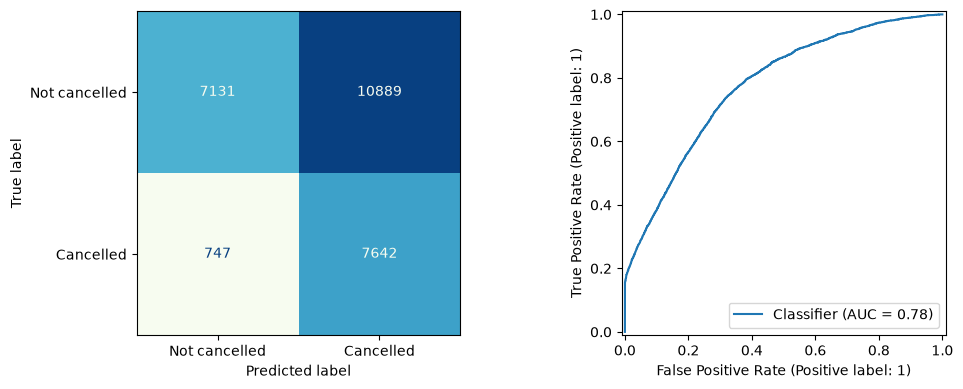

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
fig, axes = plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,probability>=bundle['threshold'],display_labels=['Not cancelled','Cancelled'],ax=axes[0],colorbar=False,cmap='GnBu')
RocCurveDisplay.from_predictions(y_test,probability,ax=axes[1])
plt.tight_layout()
plt.show()

## 7. Explain model dependence
Permutation importance shuffles one feature and measures validation AUC loss. It does not establish causal effects or explain an individual cancellation.

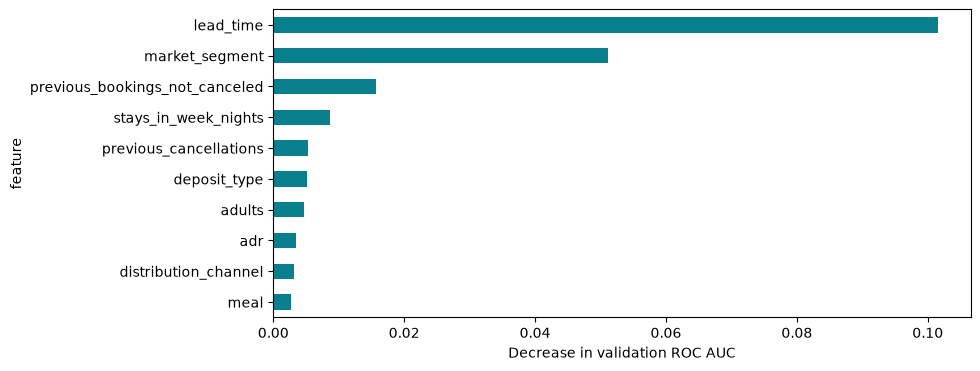

,feature,auc_decrease,std
0,lead_time,0.101502,0.008509
1,market_segment,0.051106,0.005520
2,previous_bookings_not_canceled,0.015755,0.001186
3,stays_in_week_nights,0.008734,0.000531
4,previous_cancellations,0.005310,0.001062
5,deposit_type,0.005206,0.000334
6,adults,0.004713,0.001219
7,adr,0.003430,0.001601
8,distribution_channel,0.003161,0.005444
9,meal,0.002732,0.002232


In [12]:
importance = pd.read_csv(REPORTS/'feature_importance.csv')
importance.head(10).iloc[::-1].plot.barh(x='feature',y='auc_decrease',legend=False,color='#087f8c',figsize=(9,4))
plt.xlabel('Decrease in validation ROC AUC')
plt.show()
importance.head(10)

## 8. Score a batch through the same inference path as the GUI

In [13]:
from src.model import score_bookings
examples = pd.read_csv(ROOT/'data/samples/example_bookings.csv')
predictions, warnings = score_bookings(bundle,examples)
print(warnings)
predictions[['input_row','hotel','lead_time','cancellation_probability','prediction']]

[]


,input_row,hotel,lead_time,cancellation_probability,prediction
0,1,City Hotel,63,0.397617,Likely cancelled
1,2,City Hotel,77,0.419933,Likely cancelled
2,3,City Hotel,61,0.395534,Likely cancelled
3,4,City Hotel,159,0.438525,Likely cancelled
4,5,City Hotel,0,0.189268,Likely cancelled
5,6,Resort Hotel,53,0.317403,Likely cancelled
6,7,Resort Hotel,135,0.388824,Likely cancelled
7,8,Resort Hotel,2,0.057472,Likely not cancelled
8,9,Resort Hotel,1,0.093690,Likely not cancelled
9,10,Resort Hotel,13,0.105838,Likely not cancelled


## 9. Limitations and next steps
- Two Portuguese hotels, arrivals from July 2015 to August 2017. No current or Indian-hotel validation.
- Booking creation dates are proxies: arrival date minus lead time. No booking ID verifies repeated-looking rows.
- Records lack point-in-time snapshots. A final-status timestamp and planned checkout guard earlier cohorts; prospective deployment performance is not established.
- Retained values, including deposit, price and history, are assumed to be known at booking creation. Their timing needs a real PMS audit.
- Probabilities are uncalibrated model estimates. The reliability plot and Brier score describe this test sample only.
- Cancellation does not equal no-show: some not-cancelled records have final No-Show status.

Reproduce the full model experiment with `python train.py`. Run checks with `python -m pytest -q`. For a real hotel, collect timestamped snapshots, use a genuinely separate deployment cohort, and validate probability calibration before using an operational threshold.

## References
Original data: https://doi.org/10.1016/j.dib.2018.11.126

Combined CSV and data dictionary: https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11

Scikit-learn: https://scikit-learn.org/stable/common_pitfalls.html